# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 3 - Module 3
### **Practical 3: Basic Selection Methods in Genetic Algorithms**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module III: Genetic Algorithms and Evolutionary Computing |
| **Student Name** | *Yashvi Shivhare* |
| **Enrollment No.** | *2023BTCSE021* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To implement basic selection methods for selecting suitable individuals from a population using Python.

### 2. Theory: Parent Selection Mechanisms

Selection drives evolution by favoring fitter individuals while preserving diversity:
- **Roulette Wheel:** Selection probability is proportional to raw fitness.
- **Tournament ($k=2$ or $3$):** Picks $k$ random candidates and chooses the fittest among them.
- **Rank Selection:** Assigns selection probability by sorted rank, preventing dominant individuals from taking over too early.

### 3. Step 1: Implementing Selection Operators

In [1]:
import numpy as np

np.random.seed(303)

pop = np.random.randint(0, 2, size=(10, 8))
fit = np.maximum(np.sum(pop, axis=1).astype(float), 1e-6)

def roulette_select(pop, fit, n):
    p = fit / np.sum(fit)
    idx = np.random.choice(len(pop), size=n, p=p)
    return pop[idx], idx

def tournament_select(pop, fit, n, k=2):
    chosen = []
    for _ in range(n):
        cands = np.random.choice(len(pop), size=k, replace=False)
        chosen.append(cands[np.argmax(fit[cands])])
    return pop[chosen], np.array(chosen)

def rank_select(pop, fit, n):
    ranks = np.argsort(np.argsort(fit)) + 1
    p = ranks / np.sum(ranks)
    idx = np.random.choice(len(pop), size=n, p=p)
    return pop[idx], idx

print("Fitnesses:", fit)
print("Roulette (4):", roulette_select(pop, fit, 4)[1])
print("Tournament k=2 (4):", tournament_select(pop, fit, 4, k=2)[1])
print("Rank (4):", rank_select(pop, fit, 4)[1])

Fitnesses: [4. 3. 4. 2. 3. 3. 3. 3. 4. 6.]
Roulette (4): [9 9 9 8]
Tournament k=2 (4): [0 9 8 9]
Rank (4): [8 5 9 8]


### 4. Step 2: Selection Frequency Distribution (600 Trials)

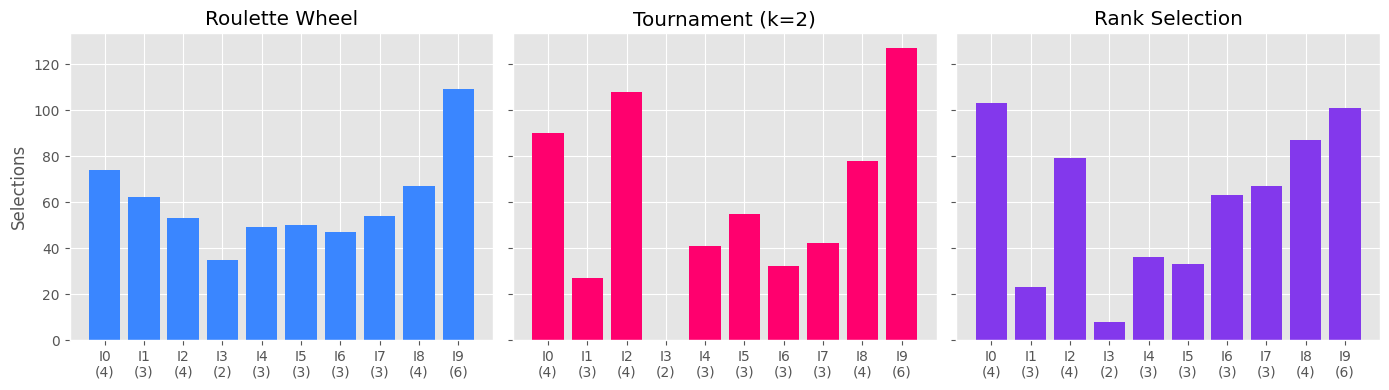

In [2]:
import matplotlib.pyplot as plt

plt.style.use('ggplot')
trials = 600
_, r_idx = roulette_select(pop, fit, trials)
_, t_idx = tournament_select(pop, fit, trials, k=2)
_, rk_idx = rank_select(pop, fit, trials)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
labels = [f"I{i}\n({int(fit[i])})" for i in range(len(pop))]

axes[0].bar(labels, np.bincount(r_idx, minlength=len(pop)), color='#3a86ff')
axes[0].set_title("Roulette Wheel")
axes[0].set_ylabel("Selections")

axes[1].bar(labels, np.bincount(t_idx, minlength=len(pop)), color='#ff006e')
axes[1].set_title("Tournament (k=2)")

axes[2].bar(labels, np.bincount(rk_idx, minlength=len(pop)), color='#8338ec')
axes[2].set_title("Rank Selection")

plt.tight_layout()
plt.show()

### 5. Conclusion
Roulette Wheel, Tournament ($k=2$), and Rank selection were implemented and compared over 600 selection trials.